In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [7]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


Part 1: Understanding Product Categories

Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

    1. Frequency Tables:
        a. Generate a frequency table for the product category.
        b. Which are the top 5 most listed product categories?
    2. Visualizations:
        a. Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart,            do it for a subset of top categories.
        b. For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [22]:
# 1.a. frequency table
frequncy_category = df["category"].value_counts()
frequncy_category 

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [28]:
# 1.b. top 5 categories are: "Sports & Outdoors", "Beauty", "Handmade Clothing, Shoes & Accessories", "Bath & Body", "Birthday Gifts"
frequncy_category.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

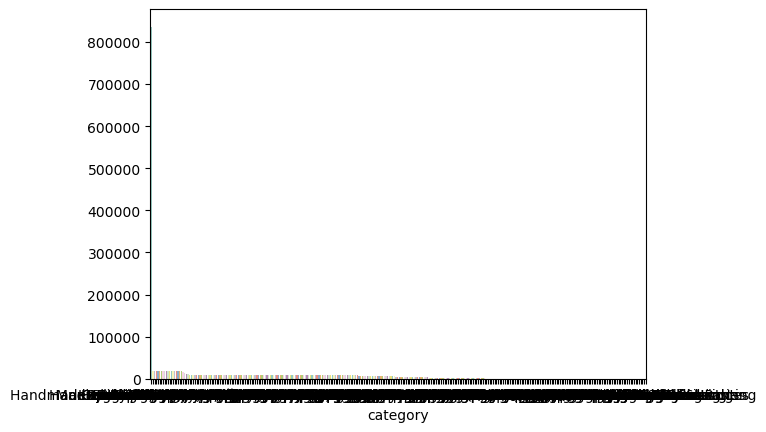

In [30]:
# 2.a. bar chart for all categories - not clear result
sns.barplot(x=frequncy_category.index, y=frequncy_category.values, palette="Set3");

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Beauty'),
  Text(2, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(3, 0, 'Bath & Body'),
  Text(4, 0, 'Birthday Gifts')])

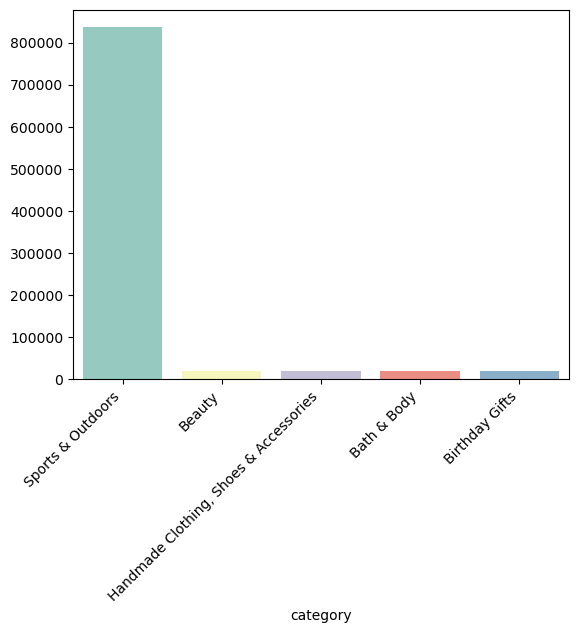

In [38]:
# 2.a. bar chart for a subset of categories
new_freq = frequncy_category.head(5)
sns.barplot(x=new_freq.index, y=new_freq.values, palette="Set3");
plt.xticks(rotation=45, ha='right')

<Axes: ylabel='count'>

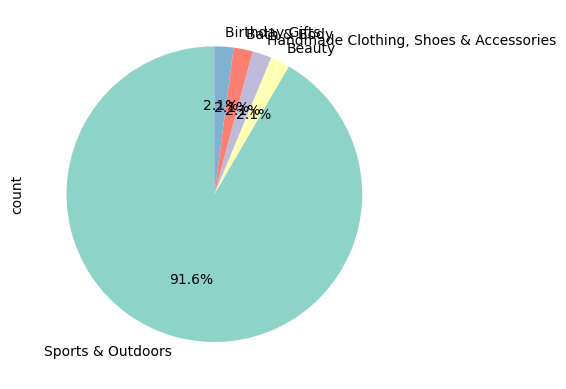

In [34]:
# 2.b. pie chart for a subset of categories 
new_freq.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

# sports&outdoor dominating with 91.6%

Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

    1. Measures of Centrality:
        a. Calculate the mean, median, and mode for the price of products.
        b. What's the average price point of products listed? How does this compare with the most common price point (mode)?

    2. Measures of Dispersion:
        a. Determine the variance, standard deviation, range, and interquartile range for product price.
        2. How varied are the product prices? Are there any indicators of a significant spread in prices?
    
    3. Visualizations:
        a. Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If               its hard to read these diagrams, think why this is, and explain how it could be solved..
        b. Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential                   outliers in product pricing.

In [81]:
# 1.a.
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(f" mean price is {mean_price}, median price is {median_price}, mode price is {mode_price}")

 mean price is 89.24380943923663, median price is 19.09, mode price is 9.99


In [ ]:
# 1.b.
# Average price point is at 89.24380943923663, the most common price (mode) is at 9.99. It means there might be positive 
# outliers that are pulling the mean up (to the right in the distribution)

In [79]:
# 2.a. 
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

print (f"variance is {variance_price}, st dev is {std_dev_price}, min price is {min_price}, max price is {max_price},range price is {range_price}, quantiles are {quantiles_price}") 
# IQR = 45.99-9.99=36.0

variance is 119445.48532256528, st dev is 345.60886175352226, min price is 0.0, max price is 100000.0,range price is 100000.0, quantiles are 0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64


In [ ]:
# 2.b. 
# median is at 19.09, the 50% of prices are in the range between 9.99 and 45,99. but the rest 50% are between 0-9.99 and 9.99-100000.
# so i would say that product prices vary sifnificantly. also std_dev_price is 345 shows how far the priced are from the median on average

<Axes: xlabel='price', ylabel='Count'>

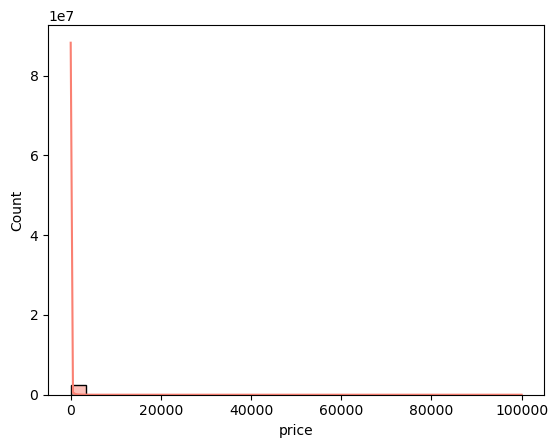

In [93]:
# 3.a. its hard to get any insight from rhis graph. may be we shoul concentrate on the prices that are below some level
sns.histplot(df['price'], kde=True, bins=30, color="salmon")

<Axes: >

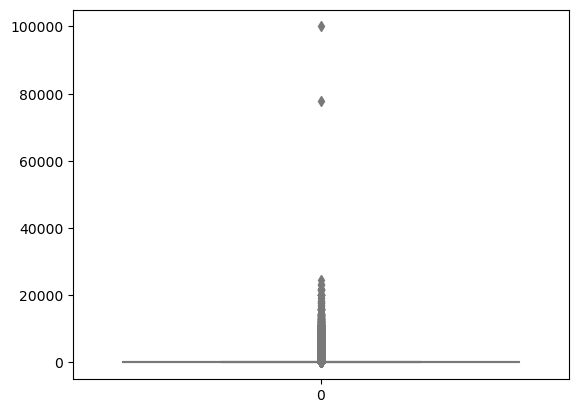

In [85]:
# 3.b. it can be noticed that in a scale of this huge outlier prices, the IQR is not to be seen. 
sns.boxplot(data = df['price'], color="lightblue")

Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

    1. Measures of Centrality:
        a. Calculate the mean, median, and mode for the rating of products.
        b. How do customers generally rate products? Is there a common trend?

    2. Measures of Dispersion:
        a. Determine the variance, standard deviation, and interquartile range for product rating.
        b. Are the ratings consistent, or is there a wide variation in customer feedback?

    3. Shape of the Distribution:
        a. Calculate the skewness and kurtosis for the rating column.
        b. Are the ratings normally distributed, or do they lean towards higher or lower values?

    4. Visualizations:
        a. Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [95]:
# 1.a.  we can see that on more often people rate the products at 0.0 stars. on average the raiting is at 2.15
mean_stars = df['stars'].mean()
median_stars = df['stars'].median()
mode_stars = df['stars'].mode()[0]
print(f" mean rating is {mean_stars}, median rating is {median_stars}, mode rating is {mode_stars}")

 mean rating is 2.152836472966065, median rating is 0.0, mode rating is 0.0


In [105]:
# 1.b.  we can see that on more often people rate the products at 0.0 stars. on average the raiting is at 2.15


In [111]:
# 2.a.
variance_stars = df['stars'].var()
std_dev_stars = df['stars'].std()
quantiles_stars = df['stars'].quantile([0.25, 0.5, 0.75])

print(f"variance is {variance_stars}, st dev is {std_dev_stars}, quantiles are {quantiles_stars}") 
# IQR = 4.4-0.0=4.4

variance is 4.81743402976196, st dev is 2.1948653785054697, quantiles are 0.25    0.0
0.50    0.0
0.75    4.4
Name: stars, dtype: float64


In [113]:
# 2.b. consistent
df['stars'].value_counts()

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

In [115]:
# 3.a.
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(0.08120735761080985, -1.9260061280432985)

In [ ]:
# 3.b
# the distribution is skewed to the rights, since the skewness is > 0
# the kurtosis is -1,92 but i can't say the distribution is normal

<Axes: xlabel='stars', ylabel='Count'>

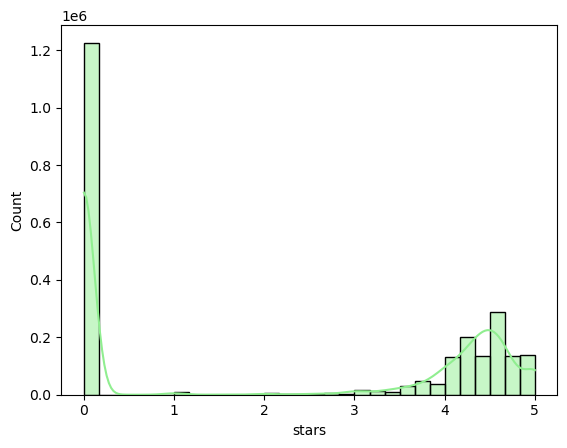

In [121]:
# 4.a.
sns.histplot(df['stars'], kde=True, bins=30, color="lightgreen")